# Evaluation 5 – Consistency and symmetry

Each question was asked **5 times to Agent-001 and 5 times to Agent-002**. The final answers are compared pair by pair.

* **Consistency** – inside one agent: does ask 1 give the same answer as asks 2, 3, 4 and 5?
* **Symmetry** – between the agents: after the KQML exchange both agents hold the same data, so every Agent-1 ask
  should give the same answer as every Agent-2 ask.

**The template for one question** (one per model):

|  |  | **Agent 1** ask 1 | ask 2 | ask 3 | ask 4 | ask 5 |
|---|---|---|---|---|---|---|
| **Agent 2** | ask 1 | score | | | | |
| | ask 2 | | | | | |
| | ask 3 | | | | | |
| | ask 4 | | | | | |
| | ask 5 | | | | | |

* **Symmetry table** – rows Agent-2 asks, columns Agent-1 asks. Symmetry = mean of the 25 cells.
* **Consistency tables** – the same layout, Agent-1 asks against Agent-1 asks, and Agent-2 against Agent-2.
  The diagonal compares an ask with itself, so consistency = mean of the cells off the diagonal.

**Score in each cell** – set with `SCORE` below:

| score | meaning |
|---|---|
| `exact` | 1 if the two answers are identical (the evaluation tool's normalised `fingerprint`), else 0 |
| `jaccard` | share of answer items the two answers have in common, \|A ∩ B\| / \|A ∪ B\| (an item = one city, one state/year/value, the status …) |
| `bertscore` | text similarity of the two answers (roberta-large, F1, rescaled) |

The notebook has three parts: **1** the template for every question, **2** the graph, **3** the reasons.

In [21]:
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SCORE = "jaccard"          # "exact", "jaccard" or "bertscore"

DATA_DIR = Path("..") / "data"
OUT_DIR = Path("outputs") / "05_consistency_symmetry"
OUT_DIR.mkdir(parents=True, exist_ok=True)
BERT_CACHE = OUT_DIR / "bertscore_cache.csv"

MODELS = ["gpt-4o-mini", "claude-haiku", "qwen3-8b", "qwen3-8b-lora"]
MODEL_LABEL = {"gpt-4o-mini": "GPT-4o mini", "claude-haiku": "Claude Haiku 5.5",
               "qwen3-8b": "Qwen3-8B", "qwen3-8b-lora": "Qwen3-8B + QLoRA"}
MODEL_COLOR = {"gpt-4o-mini": "#2a78d6", "claude-haiku": "#eb6834",
               "qwen3-8b": "#1baf7a", "qwen3-8b-lora": "#eda100"}
SCORES = ["exact", "jaccard", "bertscore"]
ASKS = [f"ask {i}" for i in range(1, 6)]

files = [f for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_*_runs-*.csv") if "summary" not in f.name]
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)
df = df.sort_values(["model", "qid", "agent_name", "rep"]).reset_index(drop=True)
questions = df.drop_duplicates("qid").set_index("qid")["question"]
QIDS = sorted(df["qid"].unique(), key=lambda q: (not q.startswith("t"), q))     # Q1 ... Q100, as in notebook 03

answer_text = df.drop_duplicates("fingerprint").set_index("fingerprint")["answer_view"]


def answer_items(value, path=""):
    # The answer as a set of items; lists are treated as unordered sets.
    if isinstance(value, dict):
        items = set()
        for key, v in value.items():
            items |= answer_items(v, f"{path}.{key}" if path else key)
        return items
    if isinstance(value, list):
        return {f"{path}[]=" + (json.dumps(v, sort_keys=True, ensure_ascii=False) if isinstance(v, (dict, list)) else str(v))
                for v in value}
    return {f"{path}={value}"}


ITEMS = {fp: answer_items(json.loads(text)) for fp, text in answer_text.items()}


def load_bertscores():
    # BERTScore only for pairs of different answers; cached so the language model runs only once.
    pairs = set()
    for _, g in df.groupby(["model", "qid"]):
        pairs |= set(combinations(sorted(g["fingerprint"].unique()), 2))
    cache = (pd.read_csv(BERT_CACHE).set_index(["fp_a", "fp_b"])["bertscore"].to_dict()
             if BERT_CACHE.exists() else {})
    todo = [p for p in sorted(pairs) if p not in cache]
    if todo:
        try:
            from bert_score import BERTScorer
        except ImportError:
            print("bert-score is not installed (pip install bert-score) - BERTScore is left empty")
            return cache
        scorer = BERTScorer(lang="en", rescale_with_baseline=True)
        _, _, f1 = scorer.score([answer_text[a] for a, _ in todo], [answer_text[b] for _, b in todo])
        cache.update(dict(zip(todo, f1.tolist())))
        pd.DataFrame([(a, b, s) for (a, b), s in cache.items()], columns=["fp_a", "fp_b", "bertscore"]).to_csv(
            BERT_CACHE, index=False)
    return cache


BERT = load_bertscores()


def pair_score(fp_a, fp_b, score):
    if fp_a == fp_b:
        return 1.0
    if score == "exact":
        return 0.0
    if score == "jaccard":
        a, b = ITEMS[fp_a], ITEMS[fp_b]
        return len(a & b) / len(a | b)
    return BERT.get(tuple(sorted((fp_a, fp_b))), np.nan)


def question_tables(model, qid, score=SCORE):
    # The template for one question and model: symmetry and the two consistency tables.
    g = df[(df["model"] == model) & (df["qid"] == qid)]
    a1 = g[g["agent_name"] == "Agent-001"]["fingerprint"].tolist()
    a2 = g[g["agent_name"] == "Agent-002"]["fingerprint"].tolist()

    def table(rows, cols):
        return pd.DataFrame([[pair_score(r, c, score) for c in cols] for r in rows], index=ASKS, columns=ASKS)

    return {"symmetry (row = Agent-2 ask, column = Agent-1 ask)": table(a2, a1),
            "consistency Agent-1 (row and column = Agent-1 ask)": table(a1, a1),
            "consistency Agent-2 (row and column = Agent-2 ask)": table(a2, a2)}


OFF_DIAGONAL = ~np.eye(5, dtype=bool)


def question_scores(tables):
    t = list(tables.values())
    return {"consistency": np.mean([t[1].values[OFF_DIAGONAL].mean(), t[2].values[OFF_DIAGONAL].mean()]),
            "symmetry": t[0].values.mean()}


print(f"{len(df)} asks, {len(QIDS)} questions, score in the tables: {SCORE}")

4000 asks, 100 questions, score in the tables: jaccard


## 1. The template for every question

One table per question: the four models side by side, and for each model the symmetry table and the two consistency
tables. Cells below 1 are coloured. The line above the table gives each model's consistency and symmetry for the
question.

In [22]:
def highlight(v):
    return "background-color: #f6c7c7" if isinstance(v, float) and v < 1 else ""


def show_template(n, qid, score=SCORE):
    blocks, line = {}, []
    for model in MODELS:
        tables = question_tables(model, qid, score)
        s = question_scores(tables)
        line.append(f"{MODEL_LABEL[model]}: consistency {s['consistency']:.3f}, symmetry {s['symmetry']:.3f}")
        blocks[MODEL_LABEL[model]] = pd.concat(tables)
    print(f"Q{n} · {qid} · {questions[qid]}")
    print("   " + "\n   ".join(line))
    display(pd.concat(blocks, axis=1).style.format("{:.3f}").map(highlight))


for n, qid in enumerate(QIDS, start=1):
    show_template(n, qid)

Q1 · t001 · What was the population of Brandenburg in 2018?
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q2 · t002 · How many marriages took place in Sachsen-Anhalt in 2016?
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q3 · t003 · Give me the live births in Rheinland-Pfalz for 2019.
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q4 · t004 · Population of Hamburg and Bremen in 2020
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q5 · t005 · Show the marriages in Bayern from 2016 to 2019.
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q6 · t006 · How many babies were born in Schleswig-Holstein in 2017 and 2018?
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


... (90 outputs left out)

Q97 · t099 · Who won the 2014 football World Cup?
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q98 · t100 · Which states border Texas?
   GPT-4o mini: consistency 0.600, symmetry 0.680
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q99 · q-ee68a1a070 · Give me the point for Hamburg, the city
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


Q100 · q-f21a844357 · Show me cities within 60 km of Hannover?
   GPT-4o mini: consistency 1.000, symmetry 1.000
   Claude Haiku 5.5: consistency 1.000, symmetry 1.000
   Qwen3-8B: consistency 1.000, symmetry 1.000
   Qwen3-8B + QLoRA: consistency 1.000, symmetry 1.000


## 2. Graph

Consistency and symmetry of every question and model. The height of a bar is the **disagreement** (1 − score):
a question where all 10 asks agree has no bar, so only the questions with a problem stand up.

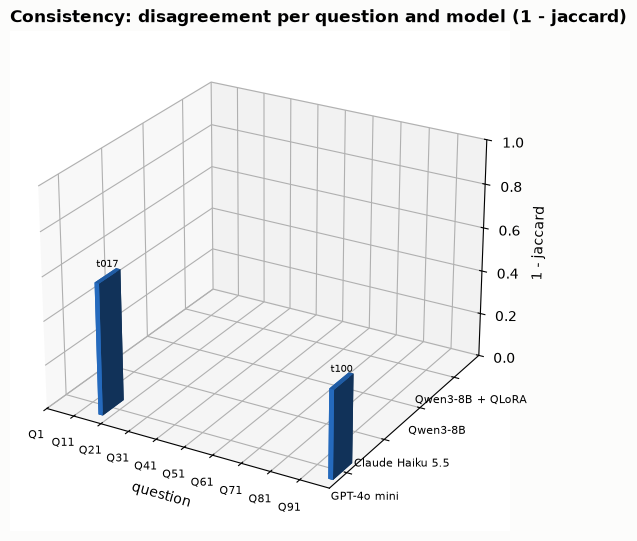

below 1: GPT-4o mini t017 (0.400), GPT-4o mini t100 (0.600)


In [23]:
rows = []
for model in MODELS:
    for qid in QIDS:
        row = {"model": model, "qid": qid}
        for score in SCORES:
            s = question_scores(question_tables(model, qid, score))
            row[f"consistency_{score}"] = s["consistency"]
            row[f"symmetry_{score}"] = s["symmetry"]
        rows.append(row)
per_question = pd.DataFrame(rows)


def overview_3d(measure, score=SCORE):
    fig = plt.figure(figsize=(14, 6.5), facecolor="#fcfcfb")
    ax = fig.add_subplot(projection="3d")
    for y, model in enumerate(MODELS):
        values = per_question[per_question["model"] == model].set_index("qid").loc[QIDS, f"{measure}_{score}"]
        groups = []          # neighbouring bars share one label
        for x, (qid, v) in enumerate(values.items()):
            if v < 1:
                ax.bar3d(x, y, 0, 1.6, 0.5, 1 - v, color=MODEL_COLOR[model], shade=True)
                if 1 - v >= 0.1:
                    if groups and x - groups[-1]["x"][-1] <= 3:
                        groups[-1]["x"].append(x)
                        groups[-1]["qids"].append(qid)
                        groups[-1]["h"] = max(groups[-1]["h"], 1 - v)
                    else:
                        groups.append({"x": [x], "qids": [qid], "h": 1 - v})
        for grp in groups:
            ax.text(np.mean(grp["x"]) + 0.8, y + 0.25, grp["h"] + 0.04, ", ".join(grp["qids"]), fontsize=7,
                    ha="center")
    ax.set_xlim(0, len(QIDS))
    ax.set_ylim(-0.2, len(MODELS))
    ax.set_zlim(0, 1)
    ax.set_yticks(np.arange(len(MODELS)) + 0.25, [MODEL_LABEL[m] for m in MODELS], fontsize=8)
    ticks = list(range(0, len(QIDS), 10))
    ax.set_xticks(ticks, [f"Q{t + 1}" for t in ticks], fontsize=8)
    ax.set_xlabel("question")
    ax.set_zlabel(f"1 - {score}")
    ax.view_init(elev=25, azim=-60)
    ax.set_title(f"{measure.capitalize()}: disagreement per question and model (1 - {score})",
                 loc="left", fontweight="bold")
    fig.savefig(OUT_DIR / f"{measure}_{score}.png", dpi=200, bbox_inches="tight")
    plt.show()
    low = per_question[per_question[f"{measure}_{score}"] < 1]
    print("below 1: " + (", ".join(f"{MODEL_LABEL[m]} {q} ({v:.3f})" for m, q, v in
                                   zip(low["model"], low["qid"], low[f"{measure}_{score}"])) or "none"))


overview_3d("consistency")

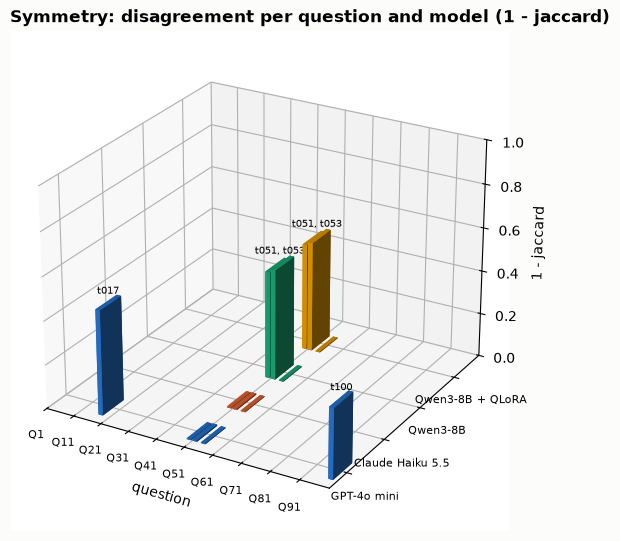

below 1: GPT-4o mini t017 (0.520), GPT-4o mini t051 (0.996), GPT-4o mini t053 (0.994), GPT-4o mini t056 (0.996), GPT-4o mini t100 (0.680), Claude Haiku 5.5 t051 (0.996), Claude Haiku 5.5 t053 (0.994), Claude Haiku 5.5 t056 (0.996), Qwen3-8B t051 (0.508), Qwen3-8B t053 (0.492), Qwen3-8B t056 (0.996), Qwen3-8B + QLoRA t051 (0.508), Qwen3-8B + QLoRA t053 (0.492), Qwen3-8B + QLoRA t056 (0.996)


In [24]:
overview_3d("symmetry")

In [25]:
g = per_question.groupby("model")
summary = pd.DataFrame({
    "questions fully consistent": g[f"consistency_{SCORE}"].apply(lambda s: (s == 1).sum()),
    "questions fully symmetric": g[f"symmetry_{SCORE}"].apply(lambda s: (s == 1).sum()),
    f"mean consistency ({SCORE})": g[f"consistency_{SCORE}"].mean(),
    f"mean symmetry ({SCORE})": g[f"symmetry_{SCORE}"].mean(),
}).reindex(MODELS)
summary.rename(index=MODEL_LABEL).round(4)

,questions fully consistent,questions fully symmetric,mean consistency (jaccard),mean symmetry (jaccard)
model,,,,
GPT-4o mini,98,95,0.99,0.9919
Claude Haiku 5.5,100,97,1.00,0.9999
Qwen3-8B,100,97,1.00,0.9900
Qwen3-8B + QLoRA,100,97,1.00,0.9900


## 3. Reasons

Every question and model below 1, with the reason found in the manual review (notebooks 03 and 04). The three scores
are given side by side so they can be compared.

| question | model | what happened | why | kind |
|---|---|---|---|---|
| t017 Population of Bavaria in 2030 | GPT-4o mini | 6 asks answered *not-found*, 4 asks were *rejected* | in those 4 asks the model dropped the year 2030 during extraction, so the agent asked for a year instead of searching | consistency – **model** |
| t100 Which states border Texas? | GPT-4o mini | 8 asks *rejected* the question, 2 ran an adjacency query (*not-found*) | the model was unsure whether the question is out of scope | consistency – **model** |
| t051, t053 City lists north / south of a state | GPT-4o mini, Claude Haiku | Agent-001 misses 5 of 1 195 and 6 of 1 075 cities; Agent-002 is complete | Agent-001 asks Agent-002 for the cities it lacks and sends the names it already has (*exclude list*); same-name cities (Essen, Münster, Fürth …) in Agent-001 hid the other city of that name | symmetry – **system** |
| t051, t053 | Qwen3-8B, Qwen3-8B + QLoRA | Agent-001 returns only 606 of 1 195 and 528 of 1 075 cities | the peer answered **HTTP 500** three times, so no cities came back – but the answer was still marked complete | symmetry – **system** |
| t056 Which cities are in Baden-Württemberg? | all four models | Agent-001 has 280 cities, Agent-002 281 | the second city named Weingarten was hidden by the name-only exclude list | symmetry – **system** |

**In short:** consistency problems come from the model (only GPT-4o mini, 2 questions); symmetry problems come from the
system and hit every model on the same three questions.

In [26]:
REASON = {("gpt-4o-mini", "t017"): "model dropped the year 2030 in 4 asks -> rejected instead of not-found",
          ("gpt-4o-mini", "t100"): "'Texas' rejected in 8 asks, searched in 2"}
for m in ["gpt-4o-mini", "claude-haiku"]:
    REASON[(m, "t051")] = REASON[(m, "t053")] = "exclude list by name hid same-name cities (5-6 missing)"
for m in ["qwen3-8b", "qwen3-8b-lora"]:
    REASON[(m, "t051")] = REASON[(m, "t053")] = "peer answered HTTP 500 -> about half the cities missing"
for m in MODELS:
    REASON[(m, "t056")] = "exclude list by name hid the second Weingarten"

cols = [f"{k}_{s}" for k in ("consistency", "symmetry") for s in SCORES]
differ = per_question[(per_question[cols] < 1).any(axis=1)].copy()
differ["reason"] = [REASON.get((m, q), "") for m, q in zip(differ["model"], differ["qid"])]
differ["model"] = differ["model"].map(MODEL_LABEL)
differ[["model", "qid"] + cols + ["reason"]].round(3)

,model,qid,consistency_exact,consistency_jaccard,consistency_bertscore,symmetry_exact,symmetry_jaccard,symmetry_bertscore,reason
16,GPT-4o mini,t017,0.4,0.4,0.556,0.52,0.520,0.645,model dropped the year 2030 in 4 asks -> rejected instead of not-found
48,GPT-4o mini,t051,1.0,1.0,1.000,0.00,0.996,1.000,exclude list by name hid same-name cities (5-6 missing)
50,GPT-4o mini,t053,1.0,1.0,1.000,0.00,0.994,1.000,exclude list by name hid same-name cities (5-6 missing)
53,GPT-4o mini,t056,1.0,1.0,1.000,0.00,0.996,1.000,exclude list by name hid the second Weingarten
97,GPT-4o mini,t100,0.6,0.6,0.717,0.68,0.680,0.774,"'Texas' rejected in 8 asks, searched in 2"
148,Claude Haiku 5.5,t051,1.0,1.0,1.000,0.00,0.996,1.000,exclude list by name hid same-name cities (5-6 missing)
150,Claude Haiku 5.5,t053,1.0,1.0,1.000,0.00,0.994,1.000,exclude list by name hid same-name cities (5-6 missing)
153,Claude Haiku 5.5,t056,1.0,1.0,1.000,0.00,0.996,1.000,exclude list by name hid the second Weingarten
248,Qwen3-8B,t051,1.0,1.0,1.000,0.00,0.508,0.842,peer answered HTTP 500 -> about half the cities missing
250,Qwen3-8B,t053,1.0,1.0,1.000,0.00,0.492,0.866,peer answered HTTP 500 -> about half the cities missing


In [27]:
# Export: the templates of all questions (one Excel file per score, one sheet per model) and the results.
for score in SCORES:
    with pd.ExcelWriter(OUT_DIR / f"tables_{score}.xlsx") as xl:
        for model in MODELS:
            sheet = MODEL_LABEL[model].replace("+", "plus")[:31]
            row = 0
            for n, qid in enumerate(QIDS, start=1):
                pd.DataFrame([[f"Q{n} · {qid}: {questions[qid]}"]]).to_excel(
                    xl, sheet_name=sheet, startrow=row, header=False, index=False)
                col = 0
                for name, t in question_tables(model, qid, score).items():
                    pd.DataFrame([[name]]).to_excel(xl, sheet_name=sheet, startrow=row + 1, startcol=col,
                                                    header=False, index=False)
                    t.round(3).to_excel(xl, sheet_name=sheet, startrow=row + 2, startcol=col)
                    col += 8
                row += 10

with pd.ExcelWriter(OUT_DIR / "consistency_symmetry.xlsx") as xl:
    summary.rename(index=MODEL_LABEL).round(4).to_excel(xl, sheet_name="summary")
    differ.round(4).to_excel(xl, sheet_name="reasons", index=False)
    per_question.assign(model=per_question["model"].map(MODEL_LABEL)).round(4).to_excel(
        xl, sheet_name="per_question", index=False)
print("saved to", OUT_DIR)

saved to outputs\05_consistency_symmetry
